<a href="https://colab.research.google.com/github/sebastianvettel1212/scikit-learn-cookbook/blob/main/scikit_learn_Cookbook_Chapter8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 8 — Algoritma Berbasis Pohon dan Metode Ensemble (*Tree-Based Algorithms and Ensemble Methods*)

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt Publishing)

Notebook ini berisi:
1. **Reproduksi kode** seluruh *recipe* Bab 8 (dari repositori resmi buku, termasuk solusi latihan),
2. **Ringkasan** tiap subbab, dan
3. **Penjelasan teori** dalam Bahasa Indonesia.

> Sel berlabel **"Tambahan"** adalah contoh pelengkap yang tidak ada di buku. Perbaikan kecil terhadap kode asli buku ditandai dengan komentar `# Catatan:` di dalam sel. (Judul notebook resmi Bab 8 di repositori buku tertulis "Chapter 8: Support Vector Machines and Kernel Methods", yang keliru; judul yang benar adalah *Tree-Based Algorithms and Ensemble Methods*.)

---

## Daftar Isi
0. Persiapan
1. Pengantar Pohon Keputusan (*Introduction to Decision Trees*)
2. *Random Forest* dan *Bagging*
3. *Gradient Boosted Machines*
4. Penyetelan Hiperparameter untuk Pohon dan Ensemble
5. Membandingkan Metode Ensemble
6. Latihan Praktik
7. Ringkasan Bab

---

## Pengantar
Bab 5–7 memakai model dengan batas keputusan berbentuk persamaan (linear atau kernel). **Pohon keputusan** bekerja dengan cara berbeda: membagi data berulang kali memakai aturan "jika-maka" sederhana. Satu pohon mudah dipahami tetapi rentan *overfitting*, maka dalam praktik pohon dipakai sebagai **komponen ensemble**: banyak model dilatih lalu digabungkan sehingga hasilnya lebih stabil dan akurat ("dua kepala lebih baik daripada satu"). Bab ini membahas **bagging** (*random forest*), **boosting** (*gradient boosting*), dan **stacking**.

## 0. Persiapan

In [1]:
!pip install numpy pandas scikit-learn matplotlib seaborn

In [2]:
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print('Versi scikit-learn:', sklearn.__version__)

def styled_report(report_dict):
    """Ubah classification_report(output_dict=True) menjadi tabel berwarna."""
    df_ = pd.DataFrame(report_dict).transpose()
    return (df_.style
        .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
        .format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1-score': '{:.3f}', 'support': '{:.0f}'}))

Versi scikit-learn: 1.6.1


---
## 1. Pengantar Pohon Keputusan (*Introduction to Decision Trees*)

### Teori
Pohon keputusan membagi data secara **rekursif** berdasarkan nilai fitur. Setiap ***internal node*** berisi satu pertanyaan (mis. "*petal width* ≤ 0,8?"), setiap ***branch*** adalah jawabannya, dan setiap ***leaf node*** berisi prediksi akhir. Pada tiap simpul, algoritma (CART) mencari fitur dan ambang yang membuat anak-anak simpul **paling homogen**.

**Ukuran ketidakmurnian (*impurity*)** untuk klasifikasi, dengan $p_k$ = proporsi kelas $k$ pada simpul:
$$\text{Gini}=1-\sum_{k=1}^{K}p_k^{2}\qquad\qquad \text{Entropi}=-\sum_{k=1}^{K}p_k\log_2 p_k$$
Keduanya bernilai 0 bila simpul **murni** (satu kelas) dan maksimum bila kelas bercampur merata. Gini adalah bawaan scikit-learn (`criterion='gini'`). Kualitas sebuah pembagian diukur dari **penurunan impurity** (*information gain*) terhadap simpul induknya:
$$\Delta I = I(\text{induk})-\Big[\tfrac{n_{kiri}}{n}I(\text{kiri})+\tfrac{n_{kanan}}{n}I(\text{kanan})\Big]$$
Untuk **regresi** (`DecisionTreeRegressor`), impurity-nya adalah MSE dan prediksi daun adalah rata-rata target di daun tersebut.

Tanpa pembatasan, pohon terus membelah hingga setiap daun murni, artinya **menghafal data latih** (variansi tinggi, *overfitting*). Kompleksitas dikendalikan dengan hiperparameter berikut (dari buku):

| Hiperparameter | Fungsi |
|---|---|
| `max_depth` | batas jumlah level pembagian |
| `min_samples_split` | jumlah minimum sampel agar simpul boleh dibagi lagi |
| `min_samples_leaf` | jumlah minimum sampel pada setiap daun |
| `max_features` | jumlah maksimum fitur yang dipertimbangkan di tiap pembagian |
| `min_impurity_decrease` | penurunan impurity minimum agar pembagian dilakukan |

| Kelebihan | Kekurangan |
|---|---|
| Mudah ditafsirkan dan divisualisasikan | Mudah *overfitting* bila tidak dibatasi |
| Tidak perlu *scaling* fitur | Tidak stabil: perubahan kecil data bisa mengubah struktur pohon |
| Menangani fitur numerik dan kategorikal serta hubungan non-linear | Batas keputusan "berundak" (sejajar sumbu) |

### Getting ready
Dataset **Iris** dipakai untuk klasifikasi.

In [3]:
# Load libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)
print('Bentuk data latih:', X_train.shape, '| data uji:', X_test.shape)

Bentuk data latih: (105, 4) | data uji: (45, 4)


### How to do it
Kita membangun pohon keputusan, melatihnya, lalu mengevaluasi kinerjanya.

In [4]:
# Instantiate the model
clf = DecisionTreeClassifier(random_state=2024)

# Fit the model to the training data
clf.fit(X_train, y_train)

# Generate predictions
y_pred = clf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

# Create a classification report
report = classification_report(y_test, y_pred, output_dict=True)
print(f'Accuracy: {accuracy:.3f}')
print(f'Kedalaman pohon: {clf.get_depth()} | jumlah daun: {clf.get_n_leaves()}')
display(styled_report(report))

Accuracy: 0.867
Kedalaman pohon: 4 | jumlah daun: 5


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.714,0.833,0.769,12
2,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


**Interpretasi:** pohon tanpa pembatasan mencapai akurasi **0,867** (39 dari 45) dengan kedalaman 4 dan hanya 5 daun; Iris cukup mudah sehingga pohon berhenti sendiri setelah semua daun murni. *Setosa* sempurna, sedangkan kesalahan ada pada *Versicolor* (precision 0,714) dan *Virginica* (recall 0,733). Pohon tunggal ini lebih lemah daripada model pada bab sebelumnya (SVM 0,93–0,96), sebuah gambaran kecil bahwa pohon tunggal bervariansi tinggi.

### How it works
Pohon membelah data agar tiap subkelompok **semakin homogen**. Kita dapat memvisualisasikan pohonnya. Cara membaca setiap simpul (dari buku):
- **Feature name:** fitur dan ambang yang dipakai membagi, mis. `petal width (cm) <= 0.8`.
- **Gini:** kemurnian simpul; 0 berarti hanya satu kelas.
- **Samples:** proporsi data latih yang sampai di simpul tersebut (`proportion=True`).
- **Value:** proporsi tiap kelas pada simpul.
- **Class:** kelas mayoritas pada simpul (menjadi prediksi bila simpul itu daun).

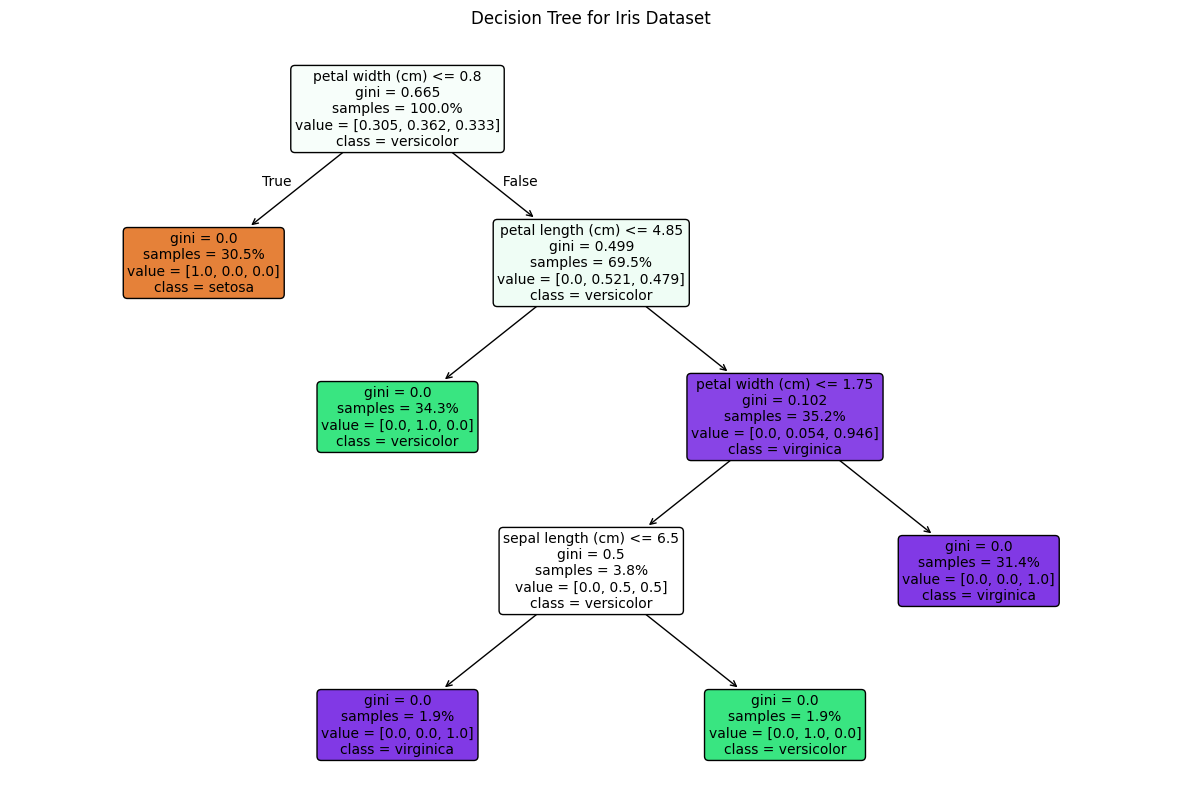

In [5]:
# Load the libraries
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Plot the figure
plt.figure(figsize=(15,10))
plot_tree(clf, feature_names=iris.feature_names, class_names=iris.target_names, filled=True, proportion=True, rounded=True, fontsize=10)
plt.title("Decision Tree for Iris Dataset")
plt.show()

**Interpretasi:** simpul akar membagi data berdasarkan `petal width`, yang langsung memisahkan *Setosa* (murni, Gini 0). Pembagian berikutnya memakai `petal length` dan `petal width` untuk membedakan *Versicolor* dan *Virginica*; simpul yang masih bercampur punya nilai Gini > 0 dan dibagi lagi hingga murni. Fitur *sepal* tidak dipakai sama sekali, konsisten dengan temuan Bab 6 bahwa fitur *petal* paling informatif. Warna menunjukkan kelas mayoritas, dan intensitasnya menunjukkan kemurnian simpul.

### Tambahan: aturan pohon sebagai teks dan pengaruh `max_depth`
Pohon dangkal (`max_depth=3`) dapat dibaca sebagai aturan "jika-maka". Selanjutnya kurva validasi pada Breast Cancer memperlihatkan hubungan kedalaman dengan *overfitting*.

|--- petal width (cm) <= 0.80
|   |--- class: 0
|--- petal width (cm) >  0.80
|   |--- petal length (cm) <= 4.85
|   |   |--- class: 1
|   |--- petal length (cm) >  4.85
|   |   |--- petal width (cm) <= 1.75
|   |   |   |--- class: 1
|   |   |--- petal width (cm) >  1.75
|   |   |   |--- class: 2

Akurasi uji pohon max_depth=3: 0.889


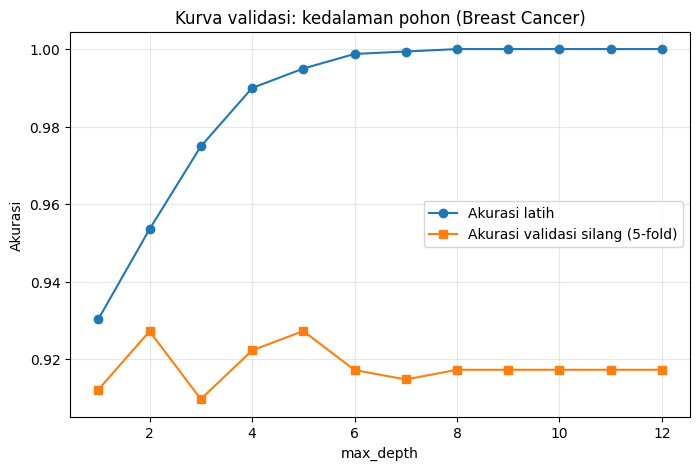

max_depth terbaik menurut CV: 5 (akurasi CV = 0.927)


In [6]:
# Tambahan (tidak ada di kode buku): aturan teks dari pohon dangkal
from sklearn.tree import export_text
shallow = DecisionTreeClassifier(max_depth=3, random_state=2024).fit(X_train, y_train)
print(export_text(shallow, feature_names=iris.feature_names))
print(f'Akurasi uji pohon max_depth=3: {shallow.score(X_test, y_test):.3f}')

# Tambahan: kurva validasi max_depth pada Breast Cancer
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import validation_curve

bc = load_breast_cancer()
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(bc.data, bc.target, test_size=0.3, random_state=2024)
depths = np.arange(1, 13)
train_sc, cv_sc = validation_curve(DecisionTreeClassifier(random_state=2024), Xb_tr, yb_tr,
                                   param_name='max_depth', param_range=depths, cv=5)
plt.figure(figsize=(8, 5))
plt.plot(depths, train_sc.mean(axis=1), 'o-', label='Akurasi latih')
plt.plot(depths, cv_sc.mean(axis=1), 's-', label='Akurasi validasi silang (5-fold)')
plt.xlabel('max_depth'); plt.ylabel('Akurasi'); plt.title('Kurva validasi: kedalaman pohon (Breast Cancer)')
plt.legend(); plt.grid(alpha=0.3); plt.show()
best_d = depths[cv_sc.mean(axis=1).argmax()]
print(f'max_depth terbaik menurut CV: {best_d} (akurasi CV = {cv_sc.mean(axis=1).max():.3f})')

**Interpretasi:** aturan teks menunjukkan keseluruhan model: "jika `petal width` ≤ 0,80 → *Setosa*; selain itu, jika `petal length` ≤ 4,85 → *Versicolor*; selain itu, jika `petal width` ≤ 1,75 → *Versicolor*, sisanya *Virginica*." Pohon dibatasi `max_depth=3` justru memberi akurasi uji **0,889**, sedikit lebih baik daripada pohon penuh (0,867, selisih 1 sampel), contoh bahwa pembatasan kompleksitas dapat membantu generalisasi. Pada Breast Cancer, kurva validasi memilih **`max_depth=5`** (akurasi CV 0,927) di antara kedalaman 1–12; pohon yang terlalu dangkal *underfitting*, sedangkan pohon tanpa batas menghafal data latih (akurasi latih 1,0, lihat Latihan 1).

### Key Ideas
- Pohon keputusan = rangkaian aturan "jika-maka" yang memaksimalkan kemurnian (Gini/entropi) di tiap pembagian.
- Tidak butuh *scaling* dan mudah ditafsirkan, tetapi **mudah overfitting**; batasi dengan `max_depth`, `min_samples_leaf`, dan sebagainya.
- Satu pohon biasanya dipakai sebagai **komponen ensemble**, bukan model akhir.

---
## 2. *Random Forest* dan *Bagging*

### Teori
**Bagging** (*Bootstrap Aggregating*) mengurangi **variansi**: (1) ambil banyak sampel ***bootstrap*** (pengambilan acak **dengan pengembalian**, ukuran sama dengan data asli), (2) latih satu model (pohon) pada tiap sampel, (3) gabungkan lewat **voting mayoritas** (klasifikasi) atau **rata-rata** (regresi).

Karena pengambilan dengan pengembalian, tiap pohon hanya melihat sekitar $1-(1-\tfrac1n)^n\approx 63{,}2\%$ data unik; sisa ≈ **36,8%** (***out-of-bag***, OOB) bisa dipakai sebagai data validasi gratis (`oob_score=True`).

**Random forest** = bagging pohon + **pengacakan fitur**: pada setiap pembagian hanya sebagian fitur acak (`max_features`) yang dipertimbangkan. Ini membuat pohon-pohon **kurang berkorelasi**, sehingga rata-ratanya lebih efektif. Untuk $B$ pohon dengan variansi $\sigma^2$ dan korelasi antar-pohon $\rho$:
$$\operatorname{Var}\big(\bar f\big)=\rho\,\sigma^2+\frac{1-\rho}{B}\,\sigma^2$$
Menambah $B$ mengecilkan suku kedua; pengacakan fitur mengecilkan $\rho$ (suku pertama). Maka random forest mengurangi variansi tanpa banyak menambah bias, dan menambah jumlah pohon (`n_estimators`) tidak menyebabkan *overfitting* (hanya menambah waktu).

**Feature importance** (`feature_importances_`) pada random forest menghitung seberapa besar tiap fitur menurunkan impurity (dirata-ratakan di semua pohon). Kelemahannya, ukuran ini bisa **bias terhadap fitur dengan banyak nilai unik** dan membagi nilai antar fitur yang berkorelasi; ***permutation importance*** adalah alternatif yang lebih dapat diandalkan.

### Getting ready

In [7]:
# Load the libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

### How to do it
Kita membangun, melatih, dan mengevaluasi *random forest* dengan 100 pohon.

In [8]:
# Instantiate the model
rf_clf = RandomForestClassifier(n_estimators=100, random_state=2024)

# Fit the model to the training data
rf_clf.fit(X_train, y_train)

# Generate predictions
y_pred = rf_clf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=True)
print(f'Accuracy: {accuracy:.3f}')
display(styled_report(report))

Accuracy: 0.911


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.833,0.833,0.833,12
2,0.867,0.867,0.867,15
accuracy,0.911,0.911,0.911,1
macro avg,0.900,0.900,0.900,45
weighted avg,0.911,0.911,0.911,45


**Interpretasi:** *random forest* mencapai akurasi **0,911** (41 dari 45), naik dari 0,867 untuk pohon tunggal pada data dan pembagian yang sama. *Versicolor* dan *Virginica* sama-sama memiliki precision dan recall 0,833 dan 0,867, sedangkan *Setosa* tetap sempurna. Peningkatan 2 sampel dari 45 belum kuat sebagai bukti; perbandingan yang lebih meyakinkan ada pada sel "Tambahan".

*Random forest* membangun banyak pohon pada sampel *bootstrap* dan, di tiap pembagian, hanya mempertimbangkan subset fitur acak; ini menambah keragaman, mengurangi variansi, dan meningkatkan generalisasi. Mari lihat *feature importance*:

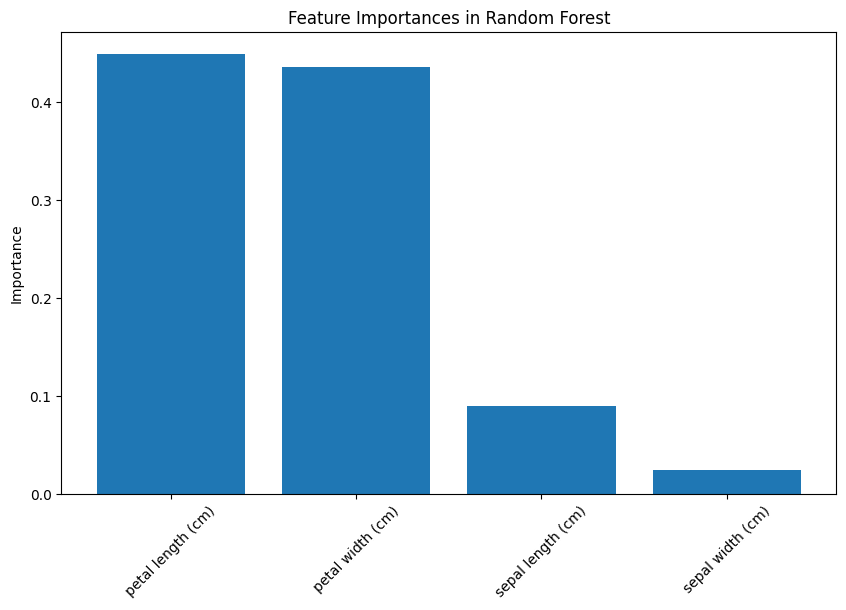

petal length (cm)    0.449
petal width (cm)     0.436
sepal length (cm)    0.090
sepal width (cm)     0.025
dtype: float64


In [9]:
# Load the libraries
import matplotlib.pyplot as plt

# Calculate feature importance
importances = rf_clf.feature_importances_
indices = np.argsort(importances)[::-1]

# Plot the feature importance
plt.figure(figsize=(10,6))
plt.title("Feature Importances in Random Forest")
plt.bar(range(X.shape[1]), importances[indices], align="center")
plt.xticks(range(X.shape[1]), [iris.feature_names[i] for i in indices], rotation=45)
plt.ylabel("Importance")
plt.show()
print(pd.Series(importances, index=iris.feature_names).sort_values(ascending=False).round(3))

**Interpretasi:** `petal length` (0,449) dan `petal width` (0,436) bersama-sama menyumbang ≈ **88,5%** pentingnya fitur, sedangkan `sepal length` (0,090) dan `sepal width` (0,025) kecil. Ini selaras dengan struktur pohon sebelumnya dan *pairplot* Bab 6. Perlu diingat, nilai ini adalah rata-rata penurunan impurity pada seluruh pohon, bukan ukuran sebab-akibat.

### Tambahan: pohon tunggal vs *bagging* vs *random forest*, skor OOB, dan *permutation importance*
Pada Iris perbedaannya tipis, maka perbandingan juga dilakukan pada Breast Cancer dengan *5-fold cross-validation*.

In [10]:
# Tambahan (tidak ada di kode buku)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.inspection import permutation_importance
from sklearn.datasets import load_breast_cancer

bc = load_breast_cancer()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)
models = {
    'Pohon tunggal': DecisionTreeClassifier(random_state=2024),
    'Bagging (100 pohon)': BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=2024),
    'Random forest (100 pohon)': RandomForestClassifier(n_estimators=100, random_state=2024),
}
rows = []
for name, m in models.items():
    s = cross_val_score(m, bc.data, bc.target, cv=cv)
    rows.append({'Model': name, 'Akurasi CV rata-rata': s.mean(), 'Simpangan baku': s.std()})
display(pd.DataFrame(rows).set_index('Model').round(3))

# Skor OOB (validasi gratis dari data yang tidak terambil bootstrap)
rf_oob = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=2024).fit(bc.data, bc.target)
print(f'Skor OOB random forest (Breast Cancer): {rf_oob.oob_score_:.3f}')

# Permutation importance vs impurity importance pada Iris
perm = permutation_importance(rf_clf, X_test, y_test, n_repeats=30, random_state=2024)
pd.DataFrame({'Impurity importance': rf_clf.feature_importances_,
              'Permutation importance': perm.importances_mean},
             index=iris.feature_names).round(3)

,Akurasi CV rata-rata,Simpangan baku
Model,,
Pohon tunggal,0.940,0.029
Bagging (100 pohon),0.952,0.032
Random forest (100 pohon),0.961,0.020


Skor OOB random forest (Breast Cancer): 0.965


,Impurity importance,Permutation importance
sepal length (cm),0.090,-0.003
sepal width (cm),0.025,-0.009
petal length (cm),0.449,0.200
petal width (cm),0.436,0.452


**Interpretasi:**
- **Perbandingan pada Breast Cancer (5-*fold* CV):** pohon tunggal 0,940 (±0,029), *bagging* 0,952 (±0,032), *random forest* **0,961** (±0,020). Urutannya sesuai teori: rata-rata banyak pohon menaikkan akurasi, dan pengacakan fitur pada *random forest* memberi hasil terbaik dengan simpangan baku terkecil (paling stabil). Skor **OOB 0,965** (validasi gratis tanpa data uji) sangat dekat dengan skor CV 0,961.
- ***Permutation importance* vs impurity:** `petal width` memang terpenting (0,452), tetapi `petal length` hanya 0,200 (impurity: 0,449). Karena keduanya berkorelasi kuat, mengacak satu fitur dikompensasi fitur lain. Fitur *sepal* bernilai ≈ 0 atau sedikit negatif (−0,003 dan −0,009), artinya mengacaknya tidak merusak prediksi, padahal impurity importance memberi nilai positif (0,090 dan 0,025). Inilah alasan impurity importance sebaiknya dikonfirmasi dengan *permutation importance*.

### Key Ideas
- **Bagging** melatih banyak model pada sampel *bootstrap* lalu merata-ratakan: mengurangi **variansi**.
- **Random forest** menambah pengacakan fitur sehingga pohon kurang berkorelasi; sangat kuat sebagai model "siap pakai".
- Skor **OOB** memberi estimasi generalisasi tanpa data validasi terpisah; `feature_importances_` berguna tetapi perlu hati-hati (pertimbangkan *permutation importance*).

---
## 3. *Gradient Boosted Machines*

### Teori
Berbeda dengan *random forest* yang membangun pohon **paralel** dan independen, ***boosting*** membangun pohon **secara berurutan**: tiap pohon baru mempelajari **kesalahan** (residu) gabungan pohon-pohon sebelumnya sehingga menurunkan **bias**. *Gradient boosting* adalah boosting yang memandang proses ini sebagai **penurunan gradien pada ruang fungsi**:

1. Mulai dari prediksi awal sederhana $F_0(x)$ (mis. rata-rata target atau log-odds kelas).
2. Untuk $m=1,\dots,M$: hitung **residu semu** $r_{im}=-\dfrac{\partial L(y_i,F(x_i))}{\partial F(x_i)}\Big|_{F=F_{m-1}}$ (untuk MSE, sama dengan $y_i-F_{m-1}(x_i)$); latih pohon dangkal $h_m$ untuk memprediksi $r_{im}$; perbarui model:
$$F_m(x)=F_{m-1}(x)+\eta\,h_m(x)$$
dengan **`learning_rate`** $\eta$ (*shrinkage*) yang mengecilkan kontribusi tiap pohon.

| Hiperparameter | Pengaruh |
|---|---|
| `n_estimators` ($M$) | jumlah pohon; terlalu banyak → *overfitting* (berbeda dengan random forest) |
| `learning_rate` ($\eta$) | kecil = belajar pelan tetapi lebih akurat, butuh lebih banyak pohon (ada *trade-off* $\eta$ vs $M$) |
| `max_depth` | kedalaman tiap pohon "lemah" (umumnya 3–5) |
| `subsample` | fraksi data tiap pohon (< 1 = *stochastic gradient boosting*) |
| `n_iter_no_change` | ***early stopping***: berhenti bila skor validasi tidak membaik |

Dua alat penting dari buku: ***early stopping*** (membatasi proses iteratif agar berhenti sebelum *overfitting*) dan ***validation curves*** (memeriksa pengaruh hiperparameter secara visual).

### Getting ready

In [11]:
# Load the libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

### How to do it...
Model *gradient boosting* dengan 1.000 pohon dan `learning_rate=0.2`.

In [12]:
# Instantiate the model
gbm_clf = GradientBoostingClassifier(n_estimators=1000, learning_rate=0.2, random_state=2024)

# Fit the model to the training data
gbm_clf.fit(X_train, y_train)

# Generate predictions
y_pred = gbm_clf.predict(X_test)

# Evaluate the model
print(f'Accuracy: {accuracy_score(y_test, y_pred):.3f}')
display(styled_report(classification_report(y_test, y_pred, output_dict=True)))

Accuracy: 0.867


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.714,0.833,0.769,12
2,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


**Interpretasi:** *gradient boosting* (1.000 pohon, `learning_rate=0.2`) mencapai akurasi **0,867**, sama dengan pohon tunggal dan lebih rendah dari *random forest* (0,911). Ini bukan bukti bahwa boosting lebih buruk: data uji hanya 45 sampel, dan konfigurasi 1.000 pohon dengan laju belajar besar pada data sekecil Iris agresif (mudah menyesuaikan diri dengan noise). Boosting biasanya baru unggul bila hiperparameternya disetel (subbab 4).

### How it works...
GBM membangun model baru yang memprediksi **residu** model sebelumnya; tiap model baru mengurangi residu itu sehingga prediksi gabungan makin akurat.

### Tambahan: kurva pembelajaran bertahap, *learning rate*, dan *early stopping*
`staged_predict()` memberi prediksi setelah tiap pohon ditambahkan, sehingga kita bisa melihat kapan model mulai *overfitting*. Dipakai Breast Cancer karena Iris terlalu mudah untuk memperlihatkan efeknya.

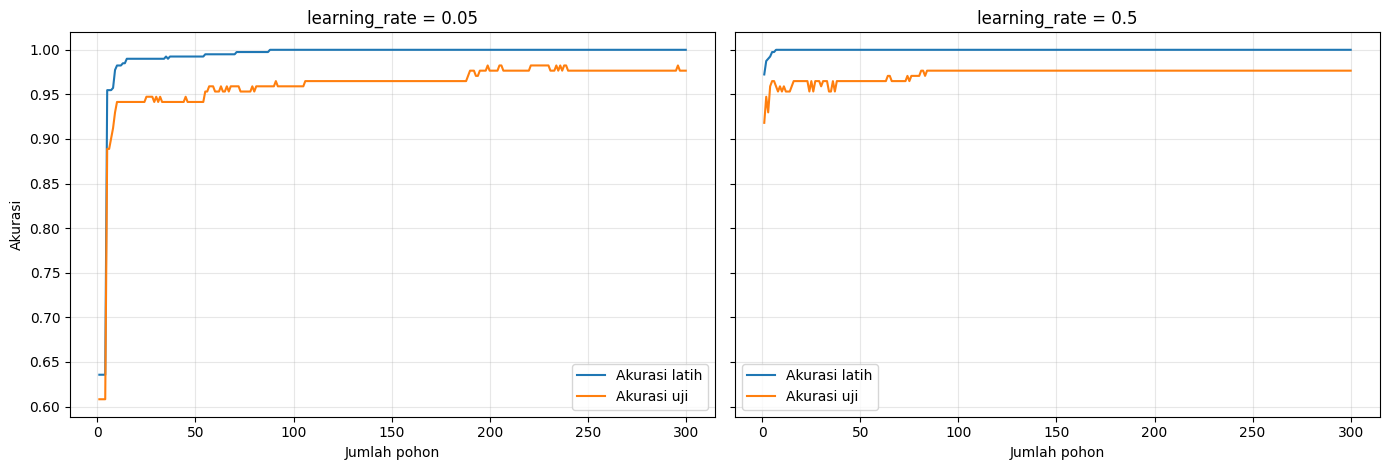

,Akurasi uji maks,Pada pohon ke-,Akurasi uji akhir (300 pohon)
learning_rate,,,
0.05,0.982,199,0.977
0.50,0.977,81,0.977


Early stopping: berhenti pada 39 dari 1000 pohon | akurasi uji = 0.947


In [13]:
# Tambahan (tidak ada di kode buku)
from sklearn.datasets import load_breast_cancer

bc = load_breast_cancer()
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(bc.data, bc.target, test_size=0.3, random_state=2024)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
summary = []
for ax, lr in zip(axes, [0.05, 0.5]):
    g = GradientBoostingClassifier(n_estimators=300, learning_rate=lr, max_depth=3, random_state=2024).fit(Xb_tr, yb_tr)
    tr = [accuracy_score(yb_tr, p) for p in g.staged_predict(Xb_tr)]
    te = [accuracy_score(yb_te, p) for p in g.staged_predict(Xb_te)]
    ax.plot(range(1, 301), tr, label='Akurasi latih'); ax.plot(range(1, 301), te, label='Akurasi uji')
    ax.set_title(f'learning_rate = {lr}'); ax.set_xlabel('Jumlah pohon'); ax.grid(alpha=0.3); ax.legend()
    summary.append({'learning_rate': lr, 'Akurasi uji maks': max(te), 'Pada pohon ke-': int(np.argmax(te)) + 1,
                    'Akurasi uji akhir (300 pohon)': te[-1]})
axes[0].set_ylabel('Akurasi'); plt.tight_layout(); plt.show()
display(pd.DataFrame(summary).set_index('learning_rate').round(3))

# Early stopping: berhenti otomatis bila skor validasi internal tidak membaik selama 10 iterasi
g_es = GradientBoostingClassifier(n_estimators=1000, learning_rate=0.1, max_depth=3, validation_fraction=0.2,
                                  n_iter_no_change=10, random_state=2024).fit(Xb_tr, yb_tr)
print(f'Early stopping: berhenti pada {g_es.n_estimators_} dari 1000 pohon | akurasi uji = {g_es.score(Xb_te, yb_te):.3f}')

**Interpretasi:** pada Breast Cancer, `learning_rate=0.05` mencapai akurasi uji maksimum **0,982** pada pohon ke-199, sedangkan `learning_rate=0.5` mencapai 0,977 lebih cepat, pada pohon ke-81. Laju belajar kecil butuh lebih banyak pohon tetapi puncaknya sedikit lebih tinggi (*trade-off* `learning_rate` vs `n_estimators`); keduanya berakhir di 0,977 pada 300 pohon, jadi pada data ini tambahan pohon tidak merusak akurasi uji secara drastis. ***Early stopping*** berhenti sangat awal, pada **39 dari 1.000 pohon**, dengan akurasi uji 0,947, lebih rendah dari puncak di atas. Alasannya: skor validasi internal dihitung dari 20% data latih (±80 sampel) sehingga bising, dan berhenti setelah 10 iterasi tanpa perbaikan terjadi cepat. Jadi `n_iter_no_change` perlu disesuaikan (mis. nilai lebih besar) agar tidak berhenti terlalu dini.

### Key Ideas
- **Gradient boosting** membangun pohon dangkal **berurutan**, masing-masing memperbaiki kesalahan pendahulunya; menurunkan **bias**.
- `learning_rate` kecil + `n_estimators` besar biasanya lebih akurat tetapi lebih lambat; keduanya harus disetel bersama.
- Gunakan ***early stopping*** dan kurva validasi untuk menghindari *overfitting*; gradient boosting lebih peka terhadap *overfitting* daripada *random forest*.

---
## 4. Penyetelan Hiperparameter untuk Pohon dan Ensemble

### Teori
Penyetelan hiperparameter memakai alat yang sama dengan bab sebelumnya (`GridSearchCV`, *cross-validation*), hanya hiperparameternya khas model pohon: kedalaman maksimum, jumlah pohon, *learning rate*, dan seterusnya. **`GridSearchCV`** menguji seluruh kombinasi pada grid dan memilih yang skor CV rata-ratanya terbaik. Jumlah model yang dilatih $=$ (jumlah kombinasi) $\times$ (jumlah *fold*), sehingga biaya tumbuh **eksponensial** terhadap jumlah hiperparameter. **`RandomizedSearchCV`** hanya mencoba `n_iter` kombinasi acak dari distribusi, sehingga lebih hemat pada ruang pencarian besar.

> **Penting:** skor CV terbaik adalah estimasi yang sedikit **optimis** (karena dipilih sebagai maksimum). Nilai performa sebenarnya dilaporkan pada **data uji yang tidak dipakai** untuk menyetel.

### Getting ready
*Gradient boosting* disetel dengan `GridSearchCV` pada Iris.

In [14]:
# Load the libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

### How to do it...
Grid search dengan *cross-validation* untuk model *gradient boosting* (3 × 3 × 3 = 27 kombinasi × 5 *fold* = 135 pelatihan).

In [15]:
# Define the hyperparameter grid
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2]
}

# Set up GridSearchCV()
grid_search = GridSearchCV(GradientBoostingClassifier(random_state=2024),
                           param_grid,
                           cv=5,
                           scoring='accuracy')

# Fit GridSearchCV() to training data
grid_search.fit(X_train, y_train)

# Identify the best parameters
print(f'Best Parameters: {grid_search.best_params_}')
print(f'Best CV score  : {grid_search.best_score_:.3f}')

# Evaluate the best model
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
print(f'Akurasi uji model terbaik: {accuracy_score(y_test, y_pred):.3f}')

# Generate classification report
display(styled_report(classification_report(y_test, y_pred, output_dict=True)))

Best Parameters: {'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 50}
Best CV score  : 0.981
Akurasi uji model terbaik: 0.867


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.714,0.833,0.769,12
2,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


**Interpretasi:** *grid search* memilih `learning_rate=0.01`, `max_depth=4`, `n_estimators=50` dengan skor CV **0,981**, tetapi akurasi uji hanya **0,867** (laporan klasifikasinya sama persis dengan model lain di bab ini). Selisih 0,981 vs 0,867 menunjukkan dua hal: skor CV terbaik bersifat optimis karena merupakan maksimum dari 27 kombinasi, dan pembagian latih/uji dengan `random_state=2024` ternyata "sulit" (semua model di bab ini berhenti di ≤ 0,911 pada 45 data uji). Satu sampel salah sama dengan 2,2 poin persentase.

### How it works...
Grid search menguji setiap kombinasi hiperparameter dengan *cross-validation*, lalu memilih kombinasi dengan skor terbaik. Visualisasi *heatmap* memperlihatkan pengaruh `max_depth` dan `n_estimators` (nilai tiap sel adalah rata-rata dari semua `learning_rate`).

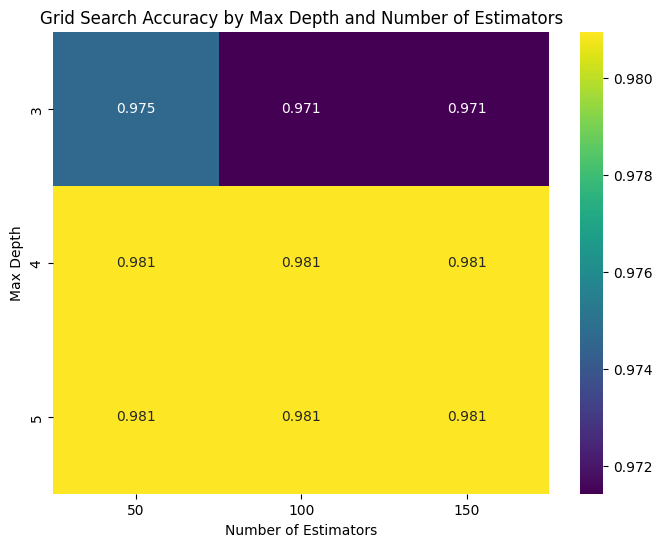

                      mean    max
param_learning_rate              
0.01                 0.977  0.981
0.10                 0.979  0.981
0.20                 0.979  0.981


In [16]:
# Load the libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Create a pivot table
results = pd.DataFrame(grid_search.cv_results_)
pivot_table = results.pivot_table(values='mean_test_score',
                                  index='param_max_depth',
                                  columns='param_n_estimators')

# Plot the heatmap
plt.figure(figsize=(8,6))
sns.heatmap(pivot_table, annot=True, fmt='.3f', cmap='viridis')
plt.title('Grid Search Accuracy by Max Depth and Number of Estimators')
plt.xlabel('Number of Estimators')
plt.ylabel('Max Depth')
plt.show()

# Tambahan: pengaruh learning_rate (rata-rata atas semua kombinasi lain)
print(results.groupby('param_learning_rate')['mean_test_score'].agg(['mean', 'max']).round(3))

**Interpretasi:** skor CV hampir seragam di seluruh sel *heatmap* (sekitar 0,97–0,98), dan rata-rata per `learning_rate` hanya berbeda tipis (0,977; 0,979; 0,979, dengan maksimum 0,981 pada ketiganya). Pada dataset sekecil dan semudah Iris, hiperparameter hampir tidak berpengaruh; penyetelan baru terasa pada data yang lebih sulit dan lebih besar.

### Tambahan: `RandomizedSearchCV` untuk *random forest* pada Breast Cancer
Ruang pencarian besar (> 300 kombinasi) dijelajahi hanya dengan 25 kombinasi acak.

In [17]:
# Tambahan (tidak ada di kode buku)
import time
from scipy.stats import randint
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_breast_cancer

bc = load_breast_cancer()
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(bc.data, bc.target, test_size=0.3, random_state=2024)

param_dist = {'n_estimators': randint(50, 400), 'max_depth': randint(2, 15),
              'min_samples_leaf': randint(1, 10), 'max_features': ['sqrt', 'log2', 0.5]}
rs = RandomizedSearchCV(RandomForestClassifier(random_state=2024), param_dist, n_iter=25, cv=5,
                        scoring='accuracy', random_state=2024, n_jobs=-1)
t0 = time.perf_counter(); rs.fit(Xb_tr, yb_tr); dur = time.perf_counter() - t0
print('Parameter terbaik:', rs.best_params_)
print(f'Skor CV terbaik: {rs.best_score_:.3f} | Akurasi uji: {rs.score(Xb_te, yb_te):.3f} | waktu: {dur:.1f} detik')

Parameter terbaik: {'max_depth': 10, 'max_features': 'log2', 'min_samples_leaf': 1, 'n_estimators': 93}
Skor CV terbaik: 0.955 | Akurasi uji: 0.947 | waktu: 58.8 detik


**Interpretasi:** dengan hanya 25 kombinasi acak, *randomized search* menemukan `n_estimators=93`, `max_depth=10`, `min_samples_leaf=1`, `max_features='log2'` dengan skor CV **0,955** dan akurasi uji **0,947**. Skor ini sedikit di bawah *random forest* default pada validasi silang sebelumnya (0,961), sebuah pengingat bahwa penyetelan tidak menjamin kenaikan besar dan hasil CV dipengaruhi variasi pembagian data. Waktu proses bergantung pada mesin (dijalankan paralel dengan `n_jobs=-1`); keuntungan utamanya adalah biaya tetap `n_iter × cv` meski ruang pencarian sangat besar.

### Key Ideas
- Gunakan *grid search* + *cross-validation* untuk `max_depth`, `n_estimators`, `learning_rate`, dll.
- `RandomizedSearchCV` lebih hemat untuk ruang pencarian besar.
- Laporkan performa akhir pada **data uji** yang tidak dipakai saat penyetelan.

---
## 5. Membandingkan Metode Ensemble

### Teori
| Metode | Cara kerja | Mengurangi | Contoh | Catatan |
|---|---|---|---|---|
| **Bagging** | model **paralel** pada sampel bootstrap, hasil dirata-ratakan/di-*vote* | **variansi** | `RandomForestClassifier`, `BaggingClassifier` | stabil, sulit *overfit*, mudah diparalelkan |
| **Boosting** | model **berurutan**, tiap model memperbaiki kesalahan sebelumnya | **bias** | `GradientBoostingClassifier`, `AdaBoostClassifier` | sering paling akurat; peka *overfitting* dan *noise*, perlu penyetelan |
| **Stacking** | **model dasar beragam** digabungkan oleh ***meta-model*** yang belajar dari prediksi mereka | keduanya (lewat keragaman) | `StackingClassifier` | lebih kompleks dan lambat; `cv` menghasilkan prediksi *out-of-fold* untuk meta-model agar tidak bocor |

Konsep dasarnya adalah dekomposisi galat: $\text{Galat}=\text{Bias}^2+\text{Variansi}+\text{Noise}$. Model sederhana (pohon dangkal) punya bias tinggi dan variansi rendah; model kompleks (pohon dalam) sebaliknya. Bagging menurunkan variansi pohon dalam; boosting menurunkan bias pohon dangkal. Tidak ada metode yang selalu terbaik: pilihan bergantung pada data, sehingga perlu dibandingkan secara empiris.

### Getting ready

In [18]:
# Load the libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

### How to do it...
Kita membangun *random forest* (bagging), *gradient boosting* (boosting), dan *stacking* (keduanya sebagai model dasar, `LogisticRegression` sebagai meta-model).

In [19]:
# Instantiate models
rf_clf = RandomForestClassifier(n_estimators=100, random_state=2024)
gb_clf = GradientBoostingClassifier(n_estimators=100, random_state=2024)
stacking_clf = StackingClassifier(
    estimators=[('rf', rf_clf), ('gb', gb_clf)],
    final_estimator=LogisticRegression(),
    cv=5
)
# Fit the models
rf_clf.fit(X_train, y_train)
gb_clf.fit(X_train, y_train)
stacking_clf.fit(X_train, y_train)

# Generate predictions
rf_pred = rf_clf.predict(X_test)
gb_pred = gb_clf.predict(X_test)
stacking_pred = stacking_clf.predict(X_test)

# Evaluate the models
rf_accuracy = accuracy_score(y_test, rf_pred)
gb_accuracy = accuracy_score(y_test, gb_pred)
stacking_accuracy = accuracy_score(y_test, stacking_pred)

# Print the accuracy scores
print(f'Random Forest Accuracy: {rf_accuracy:.2f}')
print(f'Gradient Boosting Accuracy: {gb_accuracy:.2f}')
print(f'Stacking Accuracy: {stacking_accuracy:.2f}')

Random Forest Accuracy: 0.91
Gradient Boosting Accuracy: 0.87
Stacking Accuracy: 0.87


**Interpretasi:** pada satu pembagian data, *random forest* meraih **0,91**, *gradient boosting* **0,87**, dan *stacking* **0,87**. Selisih 2 sampel dari 45 terlalu kecil untuk menyimpulkan peringkat; sel "Tambahan" membandingkannya secara lebih adil.

### How it works...
Hasilnya divisualisasikan dalam diagram batang.

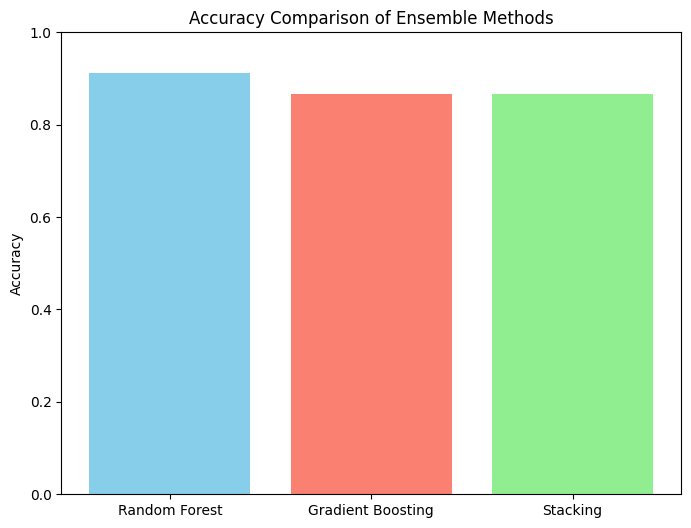

In [20]:
# Load the libraries
import matplotlib.pyplot as plt

# Create a bar plot
methods = ['Random Forest', 'Gradient Boosting', 'Stacking']
accuracies = [rf_accuracy, gb_accuracy, stacking_accuracy]

# Plot the bar plot
plt.figure(figsize=(8, 6))
plt.bar(methods, accuracies, color=['skyblue', 'salmon', 'lightgreen'])
plt.title('Accuracy Comparison of Ensemble Methods')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.show()

**Interpretasi:** karena sumbu-y dimulai dari 0 (`ylim(0, 1)`), ketiga batang tampak hampir sama tinggi, dan itulah gambaran yang jujur: perbedaan antarmetode pada Iris kecil. Memotong sumbu-y (mis. mulai 0,8) akan membuat selisih tampak jauh lebih dramatis daripada kenyataannya.

### Tambahan: perbandingan pada beberapa dataset dengan *cross-validation*
Buku menyarankan membandingkan metode pada dataset yang lebih beragam. Satu pembagian latih/uji pada 45 sampel terlalu sedikit untuk menyimpulkan; di sini dipakai *5-fold stratified cross-validation* pada tiga dataset.

In [21]:
# Tambahan (tidak ada di kode buku)
from sklearn.datasets import load_wine, load_breast_cancer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

datasets = {'Iris': load_iris(return_X_y=True),
            'Wine': load_wine(return_X_y=True),
            'Breast Cancer': load_breast_cancer(return_X_y=True)}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)
models = {
    'Pohon tunggal': DecisionTreeClassifier(random_state=2024),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=2024),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=2024),
    'Stacking': StackingClassifier(estimators=[('rf', RandomForestClassifier(n_estimators=100, random_state=2024)),
                                               ('gb', GradientBoostingClassifier(n_estimators=100, random_state=2024))],
                                   final_estimator=LogisticRegression(max_iter=5000), cv=5),
}
rows = []
for dname, (Xd, yd) in datasets.items():
    row = {'Dataset': dname}
    for mname, m in models.items():
        s = cross_val_score(m, Xd, yd, cv=cv)
        row[mname] = f'{s.mean():.3f} ± {s.std():.3f}'
    rows.append(row)
pd.DataFrame(rows).set_index('Dataset')

,Pohon tunggal,Random Forest,Gradient Boosting,Stacking
Dataset,,,,
Iris,0.953 ± 0.016,0.960 ± 0.025,0.953 ± 0.016,0.953 ± 0.016
Wine,0.922 ± 0.020,0.983 ± 0.014,0.950 ± 0.033,0.978 ± 0.021
Breast Cancer,0.940 ± 0.029,0.961 ± 0.020,0.954 ± 0.023,0.958 ± 0.018


**Interpretasi:** (akurasi CV rata-rata ± simpangan baku)
- **Iris:** semua model 0,953–0,960 dengan simpangan baku yang saling tumpang-tindih, tidak ada perbedaan nyata.
- **Wine:** ensemble jauh lebih baik daripada pohon tunggal (0,922): *random forest* **0,983**, *stacking* 0,978, *gradient boosting* 0,950.
- **Breast Cancer:** *random forest* **0,961**, *stacking* 0,958, *gradient boosting* 0,954, pohon tunggal 0,940.

*Random forest* terbaik atau setara terbaik pada ketiga dataset, *stacking* hampir selalu sama baiknya tetapi jauh lebih mahal, dan *gradient boosting* **tanpa penyetelan** tidak unggul. Seluruh ensemble mengalahkan pohon tunggal, dengan keuntungan terbesar pada Wine (+6,1 poin untuk *random forest*). Pesan buku terbukti: tidak ada metode yang selalu terbaik, jadi bandingkan secara empiris.

### Key Ideas
- **Bagging** → kurangi variansi; **boosting** → kurangi bias; **stacking** → gabungkan model beragam lewat meta-model.
- Perbandingan yang adil memerlukan **cross-validation** dan beberapa dataset, bukan satu pembagian data kecil.
- Ensemble hampir selalu mengungguli satu pohon, tetapi dengan biaya kompleksitas, waktu, dan interpretabilitas yang lebih rendah.

---
## 6. Latihan Praktik (*Practical Exercises with Tree-Based Models*)

Latihan untuk membangun, menyetel, dan mengevaluasi model berbasis pohon dan ensemble. Berikut solusi dari berkas *Exercise Solutions* repositori resmi buku, dilengkapi interpretasi.

### Latihan 1: Membangun dan Mengevaluasi *Decision Tree Classifier*
Menggunakan dataset Wine.

In [22]:
# Load libraries
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

# Load the dataset
wine = load_wine()
X = wine.data
y = wine.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train the classifier
clf = DecisionTreeClassifier(random_state=2024)
clf.fit(X_train, y_train)

# Make predictions
y_pred = clf.predict(X_test)

# Evaluate performance
print(classification_report(y_test, y_pred))
print('Akurasi latih:', round(clf.score(X_train, y_train), 3), '| kedalaman pohon:', clf.get_depth())

              precision    recall  f1-score   support

           0       1.00      0.78      0.88        18
           1       0.79      0.95      0.86        20
           2       0.94      0.94      0.94        16

    accuracy                           0.89        54
   macro avg       0.91      0.89      0.89        54
weighted avg       0.90      0.89      0.89        54

Akurasi latih: 1.0 | kedalaman pohon: 4


**Interpretasi:** pada Wine, pohon keputusan mencapai akurasi **0,89** (48 dari 54) pada data uji, tetapi akurasi latihnya **1,0**, tanda khas *overfitting* pohon tanpa batas. Kelas 0 punya precision sempurna namun recall 0,78 (beberapa sampel kelas 0 salah masuk ke kelas 1, sehingga precision kelas 1 hanya 0,79). Membatasi `max_depth` atau memakai *random forest* adalah cara menguranginya.

### Latihan 2: Penyetelan Hiperparameter *Random Forest*
Menggunakan *grid search* pada Breast Cancer.

In [23]:
# Load libraries
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Load the dataset
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Define hyperparameter grid and perform grid search
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 5, 7],
    'max_features': ['sqrt', 'log2']
}
grid_search = GridSearchCV(RandomForestClassifier(random_state=2024), param_grid, cv=5, error_score='raise')
grid_search.fit(X_train, y_train)

# Evaluate the best model
best_rf = grid_search.best_estimator_
y_pred = best_rf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f'Best Parameters: {grid_search.best_params_}')
print(f'Best CV score  : {grid_search.best_score_:.3f}')
print(f'Accuracy: {accuracy:.2f}')

Best Parameters: {'max_depth': 5, 'max_features': 'sqrt', 'n_estimators': 150}
Best CV score  : 0.955
Accuracy: 0.95


**Interpretasi:** *grid search* memilih `max_depth=5`, `max_features='sqrt'`, `n_estimators=150` dengan skor CV **0,955** dan akurasi uji **0,95**. Skor CV dan uji yang berdekatan menunjukkan model tidak *overfit*. Kedalaman 5 sejalan dengan kurva validasi pohon tunggal pada subbab 1.

### Latihan 3: Membandingkan *Gradient Boosting* dan *Random Forest*
Menggunakan dataset Digits (1.797 gambar angka 8×8, 10 kelas).

In [24]:
# Load libraries
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# Load the dataset
digits = load_digits()
X = digits.data
y = digits.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train models
import time
rf_clf = RandomForestClassifier(n_estimators=100, random_state=2024)
gb_clf = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=2024)
t0 = time.perf_counter(); rf_clf.fit(X_train, y_train); t_rf = time.perf_counter() - t0
t0 = time.perf_counter(); gb_clf.fit(X_train, y_train); t_gb = time.perf_counter() - t0

# Make predictions and evaluate
rf_pred = rf_clf.predict(X_test)
gb_pred = gb_clf.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)
gb_accuracy = accuracy_score(y_test, gb_pred)
print(f'Random Forest Accuracy: {rf_accuracy:.2f}  (waktu latih {t_rf:.1f} detik)')
print(f'Gradient Boosting Accuracy: {gb_accuracy:.2f}  (waktu latih {t_gb:.1f} detik)')

Random Forest Accuracy: 0.97  (waktu latih 0.4 detik)
Gradient Boosting Accuracy: 0.96  (waktu latih 8.2 detik)


**Interpretasi:** pada Digits (64 fitur, 10 kelas), *random forest* mencapai **0,97** dan *gradient boosting* **0,96**. Selisih akurasi kecil, tetapi biaya komputasinya berbeda jauh: *random forest* melatih pohon paralel dan independen (≈ 0,3 detik di mesin ini), sedangkan *gradient boosting* melatih secara berurutan dan membangun satu pohon per kelas pada setiap iterasi (100 × 10 = 1.000 pohon, ≈ 5 detik). Angka waktu bergantung perangkat, tetapi rasionya menggambarkan perbedaan sifat paralel vs berurutan.

---
## 7. Ringkasan Bab

Bab ini membahas model **berbasis pohon** dan cara menggabungkannya menjadi **ensemble**: pohon keputusan sebagai blok bangunan yang mudah dipahami, *random forest* (bagging) untuk menurunkan variansi, *gradient boosting* untuk menurunkan bias, serta *stacking* untuk menggabungkan model beragam, lengkap dengan penyetelan hiperparameter.

### Rangkuman Konsep dan Fungsi
| Subbab | Konsep utama | Kelas/Fungsi scikit-learn |
|---|---|---|
| Pohon keputusan | Gini/entropi, pembagian rekursif, `max_depth` dkk. | `DecisionTreeClassifier`, `plot_tree`, `export_text` |
| Random forest & bagging | Bootstrap, pengacakan fitur, OOB, *feature importance* | `RandomForestClassifier`, `BaggingClassifier`, `permutation_importance` |
| Gradient boosting | Pohon berurutan pada residu, `learning_rate`, *early stopping* | `GradientBoostingClassifier`, `staged_predict` |
| Penyetelan hiperparameter | Grid/random search + CV | `GridSearchCV`, `RandomizedSearchCV` |
| Membandingkan ensemble | Bagging vs boosting vs stacking | `StackingClassifier`, `cross_val_score` |
| Latihan | Pohon (Wine), RF tuning, GB vs RF (Digits) | `load_wine`, `load_digits` |

**Pesan utama:** satu pohon mudah dipahami tetapi rentan *overfitting*; **ensemble pohon** (random forest, gradient boosting) adalah salah satu pilihan terkuat untuk data tabular. Setel kompleksitas lewat *cross-validation* (`max_depth`, `n_estimators`, `learning_rate`), manfaatkan *early stopping* dan skor OOB, dan bandingkan metode secara empiris pada beberapa dataset; tidak ada metode yang selalu terbaik.